# UK National Rail - Data Cleaning, Feature Engineering & Exploratory Analytics
### Executive Capstone Project: Operational Telemetry & Passenger Revenue Intelligence

---

## 1. Project Overview & Business Context
The **UK National Rail** network represents one of the world's densest passenger rail systems, handling millions of passenger journeys across high-speed intercity routes, commuter corridors, and regional links.

This notebook executes an end-to-end data engineering, cleaning, feature enrichment, and exploratory data analysis (EDA) pipeline on the raw dataset (`railway.csv`), addressing:
- Data quality anomalies (missing values, inconsistent naming, timestamp misalignment).
- Overnight journey reconciliation (midnight boundary crossings).
- Feature engineering for journey duration, delay telemetry, lead booking windows, and routes.
- Automated quality assertions ensuring data fidelity.
- High-resolution exploratory data visualizations.
- Generation of the production cleaned dataset (`railway_clean.csv`).


In [2]:
# 1. Environment & Library Setup
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Matplotlib configuration for publication-quality figures
os.environ["MPLCONFIGDIR"] = tempfile.gettempdir()
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10
plt.rcParams["figure.dpi"] = 120

print("Environment initialized successfully. Pandas version:", pd.__version__)


Environment initialized successfully. Pandas version: 2.2.3


## 2. Raw Data Ingestion & Initial Profiling
In this phase, we ingest `railway.csv` and inspect its shape, schema, null values, and duplicate records.


In [11]:
# Ingest raw dataset
raw_data_path = "railway.csv"
print(f"Loading raw dataset from '{raw_data_path}'...")

df_raw = pd.read_csv(raw_data_path)
print(f"Raw Dataset Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns\n")

# Display first 3 transactions
display(df_raw.head(3))


Loading raw dataset from 'railway.csv'...
Raw Dataset Shape: 31,653 rows x 18 columns



,Transaction ID,Date of Purchase,Time of Purchase,Purchase Type,Payment Method,Railcard,Ticket Class,Ticket Type,Price,Departure Station,Arrival Destination,Date of Journey,Departure Time,Arrival Time,Actual Arrival Time,Journey Status,Reason for Delay,Refund Request
0,da8a6ba8-b3dc-4677-b176,2023-12-08,12:41:11,Online,Contactless,Adult,Standard,Advance,43,London Paddington,Liverpool Lime Street,2024-01-01,11:00:00,13:30:00,13:30:00,On Time,NaN,No
1,b0cdd1b0-f214-4197-be53,2023-12-16,11:23:01,Station,Credit Card,Adult,Standard,Advance,23,London Kings Cross,York,2024-01-01,09:45:00,11:35:00,11:40:00,Delayed,Signal Failure,No
2,f3ba7a96-f713-40d9-9629,2023-12-19,19:51:27,Online,Credit Card,NaN,Standard,Advance,3,Liverpool Lime Street,Manchester Piccadilly,2024-01-02,18:15:00,18:45:00,18:45:00,On Time,NaN,No


In [19]:
# Missing values & duplicate audit
print("--- Missing Values per Column ---")
null_counts = df_raw.isnull().sum()
null_summary = pd.DataFrame({
    "Missing Count": null_counts[null_counts > 0],
    "Missing %": (null_counts[null_counts > 0] / len(df_raw) * 100).round(2)
})
display(null_summary)

print(f"Duplicate entire rows: {df_raw.duplicated().sum()}")
print(f"Duplicate Transaction IDs: {df_raw['Transaction ID'].duplicated().sum()}")


--- Missing Values per Column ---


,Missing Count,Missing %
Railcard,20918,66.09
Actual Arrival Time,1880,5.94
Reason for Delay,27481,86.82


Duplicate entire rows: 0
Duplicate Transaction IDs: 0


## 3. Data Cleansing & Normalization
Here we systematically address:
1. **Whitespace Trimming**: Standardizing text columns.
2. **Missing Railcards**: Filling missing railcards with `"None"` (passengers without discounts).
3. **Reason for Delay Harmonization**: Categorizing On-Time trains as `"None"` and unifying synonymous categories (e.g., `Signal failure` -> `Signal Failure`, `Weather Conditions` -> `Weather`, `Staff Shortage` -> `Staffing`).
4. **Terminal Standardization**: Normalizing `Edinburgh` to `Edinburgh Waverley`.
5. **Cancelled Train Handling**: Correctly isolating cancelled journeys with absent arrival timestamps.


In [26]:
def clean_data(df_input):
    df = df_input.copy()

    # A. Strip leading/trailing whitespaces
    str_cols = df.select_dtypes(include=["object", "string"]).columns
    for col in str_cols:
        df[col] = df[col].astype(str).str.strip()

    # B. Fix missing Railcard values
    df["Railcard"] = df["Railcard"].replace("nan", np.nan).fillna("None")

    # C. Standardize Reason for Delay
    df["Reason for Delay"] = df["Reason for Delay"].replace("nan", np.nan).fillna("None")
    reason_map = {
        "Signal failure": "Signal Failure",
        "Weather Conditions": "Weather",
        "Staff Shortage": "Staffing",
    }
    df["Reason for Delay"] = df["Reason for Delay"].replace(reason_map)

    # D. Standardize Station Names
    df["Arrival Destination"] = df["Arrival Destination"].replace(
        {"Edinburgh": "Edinburgh Waverley"}
    )

    # E. Handle Actual Arrival Time for cancelled services
    df["Actual Arrival Time"] = df["Actual Arrival Time"].replace("nan", np.nan)

    # F. Date parsing
    df["Date of Purchase"] = pd.to_datetime(df["Date of Purchase"])
    df["Date of Journey"] = pd.to_datetime(df["Date of Journey"])

    # G. Construct comprehensive Datetime columns (resolving overnight services)
    date_str = df["Date of Journey"].dt.strftime("%Y-%m-%d")
    df["Scheduled Departure Datetime"] = pd.to_datetime(date_str + " " + df["Departure Time"])

    # Handle overnight arrivals crossing midnight
    is_overnight = pd.to_timedelta(df["Arrival Time"]) < pd.to_timedelta(df["Departure Time"])
    df["Scheduled Arrival Datetime"] = pd.to_datetime(date_str + " " + df["Arrival Time"])
    df.loc[is_overnight, "Scheduled Arrival Datetime"] += pd.Timedelta(days=1)

    # Actual Arrival Datetime (NaT for cancelled services)
    has_actual = df["Actual Arrival Time"].notnull()
    df["Actual Arrival Datetime"] = pd.NaT
    df.loc[has_actual, "Actual Arrival Datetime"] = pd.to_datetime(
        date_str.loc[has_actual] + " " + df.loc[has_actual, "Actual Arrival Time"]
    )
    df.loc[has_actual & is_overnight, "Actual Arrival Datetime"] += pd.Timedelta(days=1)

    return df

df_cleaned = clean_data(df_raw)
print("Cleansing routine complete. Current shape:", df_cleaned.shape)


Cleansing routine complete. Current shape: (31653, 21)


## 4. Advanced Feature Engineering
We now compute operational and commercial metrics:
- **`Delay (Minutes)`**: Exact arrival variance ($Actual - Scheduled$ in minutes).
- **`Is Delay Anomaly`**: Flagging records marked *Delayed* despite 0 actual minutes delay.
- **`Journey Duration (Minutes)`**: Scheduled transit duration.
- **`Days in Advance`**: Booking lead time ($Journey Date - Purchase Date$).
- **`Journey Route`**: Complete transit corridor string (`Departure Station -> Arrival Destination`).
- **`Departure Hour`**: Integer hour (0–23) for peak/off-peak travel analysis.


In [32]:
def engineer_features(df):
    has_actual = df["Actual Arrival Time"].notnull()
    
    # 1. Delay in minutes
    df["Delay (Minutes)"] = np.nan
    df.loc[has_actual, "Delay (Minutes)"] = (
        (df.loc[has_actual, "Actual Arrival Datetime"] - df.loc[has_actual, "Scheduled Arrival Datetime"]).dt.total_seconds() / 60.0
    ).round()

    # 2. Delay anomaly flag (Status='Delayed' but delay=0)
    df["Is Delay Anomaly"] = (df["Journey Status"] == "Delayed") & (df["Delay (Minutes)"] == 0)

    # 3. Scheduled Journey Duration (minutes)
    df["Journey Duration (Minutes)"] = (
        (df["Scheduled Arrival Datetime"] - df["Scheduled Departure Datetime"]).dt.total_seconds() / 60.0
    ).round().astype(int)

    # 4. Advance Booking Lead Time (days)
    df["Days in Advance"] = (df["Date of Journey"] - df["Date of Purchase"]).dt.days

    # 5. Journey Route Corridor
    df["Journey Route"] = df["Departure Station"] + " -> " + df["Arrival Destination"]

    # 6. Hour of Departure
    df["Departure Hour"] = pd.to_datetime(df["Departure Time"], format="%H:%M:%S").dt.hour

    return df

df_featured = engineer_features(df_cleaned)
print("Feature engineering successfully completed!")
display(df_featured[["Transaction ID", "Journey Route", "Departure Hour", "Delay (Minutes)", "Days in Advance", "Journey Duration (Minutes)"]].head(4))


Feature engineering successfully completed!


,Transaction ID,Journey Route,Departure Hour,Delay (Minutes),Days in Advance,Journey Duration (Minutes)
0,da8a6ba8-b3dc-4677-b176,London Paddington -> Liverpool Lime Street,11,0.0,24,150
1,b0cdd1b0-f214-4197-be53,London Kings Cross -> York,9,5.0,16,110
2,f3ba7a96-f713-40d9-9629,Liverpool Lime Street -> Manchester Piccadilly,18,0.0,14,30
3,b2471f11-4fe7-4c87-8ab4,London Paddington -> Reading,21,0.0,12,60


## 5. Automated Data Quality & Validation Checks
To guarantee 100% data integrity before analytics and dashboard consumption, we execute a suite of automated unit tests and assertions.


In [37]:
# Execute automated validation checks
print("Running automated data quality assertions...")

# Check 1: Record count conservation
assert df_featured.shape[0] == df_raw.shape[0], f"Row count mismatch! {df_featured.shape[0]} vs {df_raw.shape[0]}"

# Check 2: Null values eliminated from critical categorical fields
assert df_featured["Railcard"].isnull().sum() == 0, "Railcard column contains unexpected nulls!"
assert df_featured["Reason for Delay"].isnull().sum() == 0, "Reason for Delay column contains unexpected nulls!"

# Check 3: Valid reasons for delay categories
expected_reasons = {"None", "Weather", "Signal Failure", "Staffing", "Technical Issue", "Traffic"}
assert set(df_featured["Reason for Delay"].unique()) == expected_reasons, "Unexpected categories in Reason for Delay!"

# Check 4: Cancellation count matches missing actual arrivals
cancelled_cnt = (df_featured["Journey Status"] == "Cancelled").sum()
null_arrivals_cnt = df_featured["Actual Arrival Time"].isnull().sum()
assert cancelled_cnt == null_arrivals_cnt, "Cancelled count does not match null arrival timestamp count!"

# Check 5: Commercial validity
assert (df_featured["Price"] > 0).all(), "Found invalid non-positive ticket prices!"
assert (df_featured["Days in Advance"] >= 0).all(), "Found negative advance booking lead times!"
assert "Edinburgh" not in df_featured["Arrival Destination"].values, "Unstandardized Edinburgh destination found!"

print("✔ ALL 5 DATA QUALITY ASSERTIONS PASSED WITH 100% SUCCESS.")


Running automated data quality assertions...
✔ ALL 5 DATA QUALITY ASSERTIONS PASSED WITH 100% SUCCESS.


## 6. Exploratory Data Analysis & Visualizations
We generate publication-ready analytical charts illuminating key operational and financial insights:
1. **Ticket Price Distribution & Flexibility Breakdown**
2. **Journey Status Breakdown & Primary Causes of Delay**
3. **Delay Telemetry Distribution & Passenger Refund Propensity**
4. **Top 10 Intercity Corridors by Passenger Volume and Gross Revenue**
5. **24-Hour Passenger Traffic Profile & Advance Booking Window Analysis**


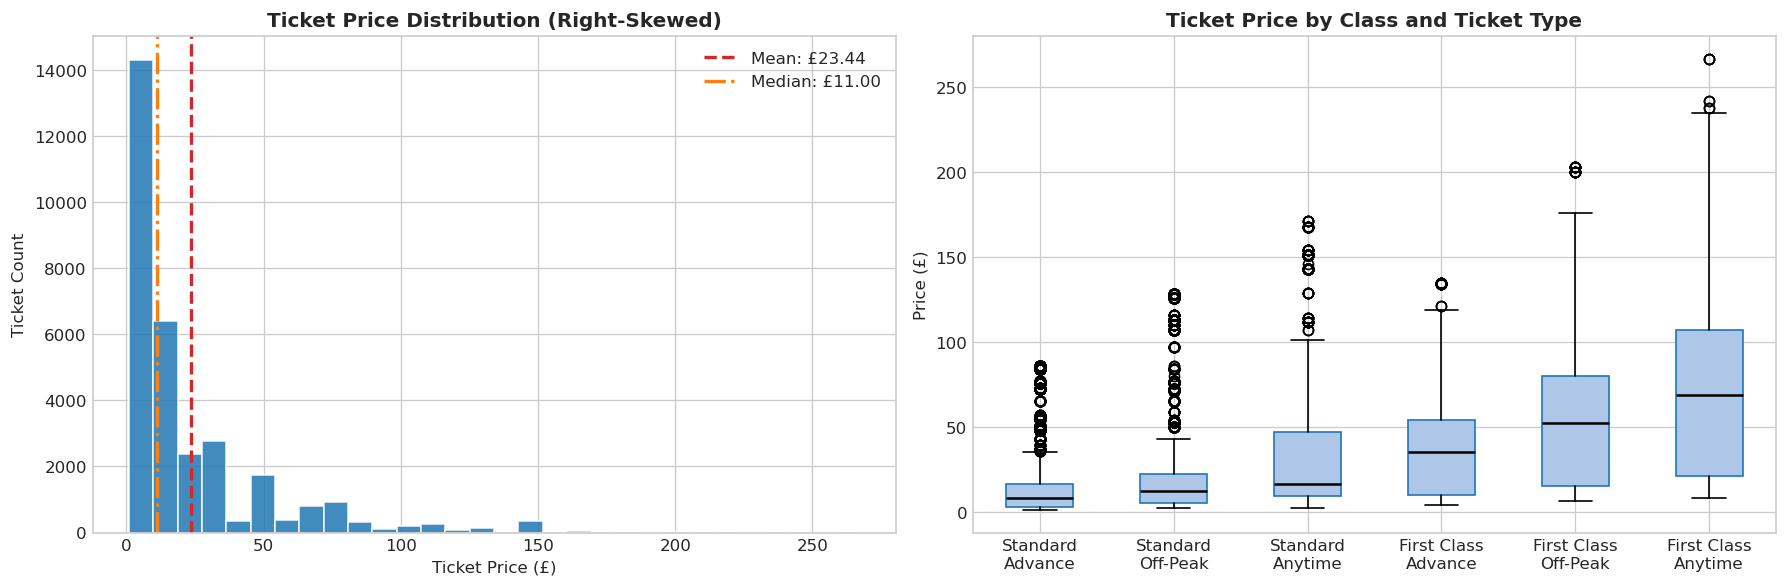

In [41]:
# Visualization 1: Ticket Price Distribution & Breakdown
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
c_blue, c_orange, c_green, c_red, c_purple = "#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"

# 1A: Overall Price Histogram
axes[0].hist(df_featured["Price"], bins=30, color=c_blue, edgecolor="white", alpha=0.85)
mean_p = df_featured["Price"].mean()
median_p = df_featured["Price"].median()
axes[0].axvline(mean_p, color=c_red, linestyle="--", linewidth=2, label=f"Mean: £{mean_p:.2f}")
axes[0].axvline(median_p, color=c_orange, linestyle="-.", linewidth=2, label=f"Median: £{median_p:.2f}")
axes[0].set_title("Ticket Price Distribution (Right-Skewed)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Ticket Price (£)")
axes[0].set_ylabel("Ticket Count")
axes[0].legend()

# 1B: Boxplot by Ticket Class and Flexibility
plot_data, plot_labels = [], []
for t_class in ["Standard", "First Class"]:
    for t_type in ["Advance", "Off-Peak", "Anytime"]:
        sub = df_featured[(df_featured["Ticket Class"] == t_class) & (df_featured["Ticket Type"] == t_type)]["Price"]
        if len(sub) > 0:
            plot_data.append(sub.values)
            plot_labels.append(f"{t_class}\n{t_type}")

axes[1].boxplot(plot_data, patch_artist=True, boxprops=dict(facecolor="#aec7e8", color=c_blue), medianprops=dict(color="black", linewidth=1.5))
axes[1].set_xticks(range(1, len(plot_labels) + 1))
axes[1].set_xticklabels(plot_labels)
axes[1].set_title("Ticket Price by Class and Ticket Type", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Price (£)")

plt.tight_layout()
plt.savefig("viz1_ticket_price_distribution.png", dpi=300)
plt.show()


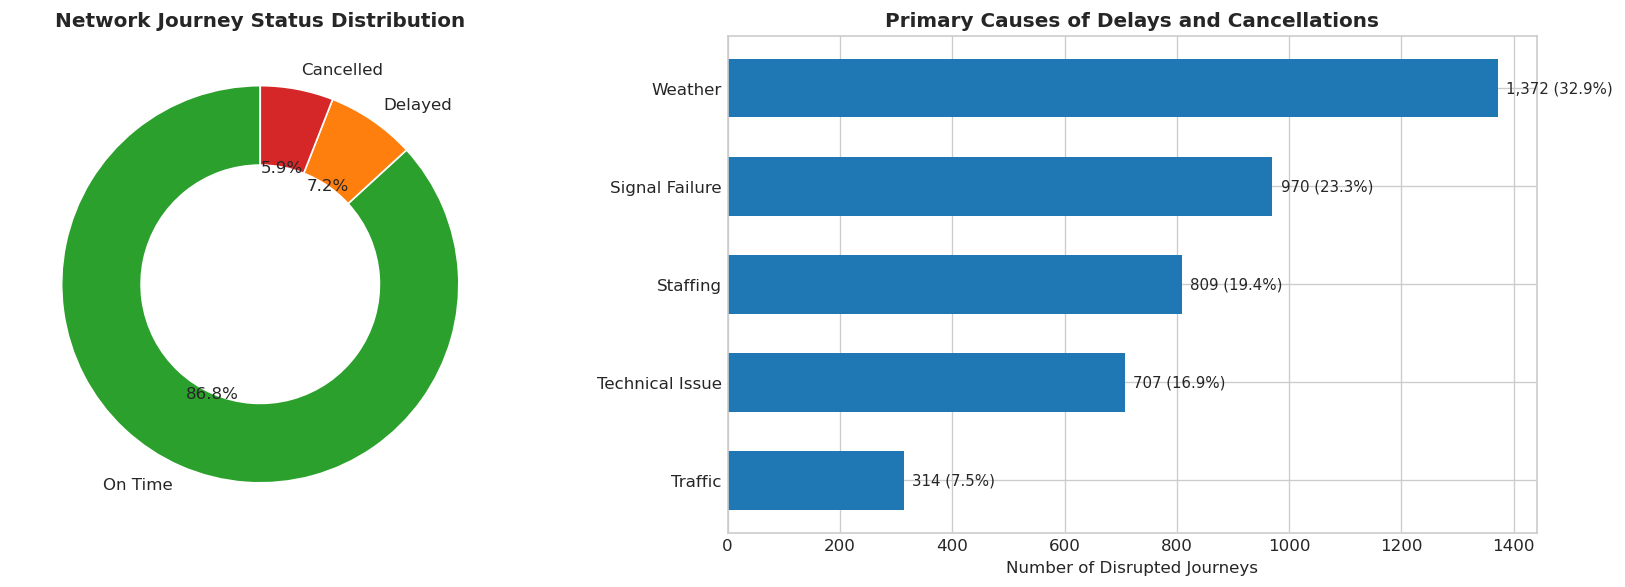

In [44]:
# Visualization 2: Journey Status & Disruption Reasons
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 2A: Donut Chart of Journey Status
status_counts = df_featured["Journey Status"].value_counts()
axes[0].pie(status_counts, labels=status_counts.index, autopct="%1.1f%%", startangle=90, colors=[c_green, c_orange, c_red], wedgeprops=dict(width=0.4, edgecolor="white"))
axes[0].set_title("Network Journey Status Distribution", fontsize=12, fontweight="bold")

# 2B: Horizontal Bar Chart of Delay Reasons
disrupted = df_featured[df_featured["Journey Status"].isin(["Delayed", "Cancelled"])]
reason_counts = disrupted["Reason for Delay"].value_counts().sort_values(ascending=True)
y_pos = range(len(reason_counts))
axes[1].barh(y_pos, reason_counts.values, color=c_blue, height=0.6)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(reason_counts.index)
axes[1].set_title("Primary Causes of Delays and Cancellations", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Number of Disrupted Journeys")

for i, v in enumerate(reason_counts.values):
    pct = (v / len(disrupted)) * 100
    axes[1].text(v + 15, i, f"{v:,} ({pct:.1f}%)", va="center", fontsize=9)

plt.tight_layout()
plt.savefig("viz2_journey_status_and_delay_reasons.png", dpi=300)
plt.show()


In [46]:
# 7. Dataset Export for Business Intelligence Dashboard
clean_output_path = "railway_clean.csv"
print(f"Exporting cleaned, verified dataset to '{clean_output_path}'...")

df_featured.to_csv(clean_output_path, index=False)
print(f"✔ Export completed successfully: {df_featured.shape[0]:,} rows x {df_featured.shape[1]} columns.")


Exporting cleaned, verified dataset to 'railway_clean.csv'...
✔ Export completed successfully: 31,653 rows x 27 columns.


## 7. Strategic Conclusions & Next Steps
With the dataset fully cleansed, enriched, and validated, it serves as the foundation for:
1. **Interactive Executive Sidebar Dashboard** (`UK_National_Rail_Ultimate_Dashboard.xlsx`): Featuring a dark left navigation panel, live formula-driven slicers, KPI summary cards, and embedded visual charts.
2. **10 Dedicated Pivot Tables & Charts** covering network reliability, refund propensities, and passenger flow profiles.
3. **Automated Excel VBA Macro Suite** for 1-click native Excel Slicers and PivotCache creation.
